# E3 — Learned Non-Diffusion Object Removal

Common pipeline:

**instruction → YOLOv8n detection → MobileSAM segmentation → removal mask → learned inpainting**

E3 replaces the slow Stable Diffusion removal stage with:
- **MI-GAN 512 ONNX** for the fast CPU/mobile-oriented path
- **LaMa / big-lama** as the quality reference

Important:
- MI-GAN ONNX uses **255 = known/keep, 0 = hole**, so our removal mask is inverted before MI-GAN.
- LaMa uses **255 = inpaint**, matching our removal mask.
- E3 is for **removal only**. Keep the existing diffusion replacement path separately.

In [4]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# E2-B: ONNX Runtime
!pip install -q -U optimum[onnxruntime] onnxruntime

# Common utilities
!pip install -q ultralytics opencv-python pillow psutil pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.2/161.2 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 70.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 82.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 90.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 95.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.2/194.2 kB 22.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompati

In [3]:
!pip uninstall -y diffusers transformers peft accelerate optimum optimum-onnx \
    sentence-transformers safetensors huggingface-hub

!pip install -U \
    "diffusers==0.40.0" \
    "transformers>=4.41.2,<6" \
    "accelerate>=1.1.0" \
    "safetensors>=0.8.0" \
    "peft>=0.20.0" \
    "huggingface-hub>=1.16.0,<2.0"

Found existing installation: diffusers 0.40.0
Uninstalling diffusers-0.40.0:
  Successfully uninstalled diffusers-0.40.0
Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: peft 0.21.0
Uninstalling peft-0.21.0:
  Successfully uninstalled peft-0.21.0
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: optimum 2.1.0
Uninstalling optimum-2.1.0:
  Successfully uninstalled optimum-2.1.0
Found existing installation: optimum-onnx 0.1.0
Uninstalling optimum-onnx-0.1.0:
  Successfully uninstalled optimum-onnx-0.1.0
Found existing installation: sentence-transformers 5.7.0
Uninstalling sentence-transformers-5.7.0:
  Successfully uninstalled sentence-transformers-5.7.0
Found existing installation: safetensors 0.8.0
Uninstalling safetensors-0.8.0:
  Successfully uninstalled safetensors-0.8.0
Fo

In [5]:
!pip install -q git+https://github.com/ChaoningZhang/MobileSAM.git

  Preparing metadata (setup.py) ... done


In [3]:
# Fix packaging tools
!pip install -q --upgrade pip setuptools wheel poetry-core

# Install the wheel directly instead of building from source
!pip install -q --only-binary=:all: simple-lama-inpainting==0.1.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 818.2/818.2 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.6/413.6 kB 9.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
torch 2.11.0+cpu requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
ERROR: Could not find a version that satisfies the requirement fire<0.6.0,>=0.5.0 (from simple-lama-inpainting) (from versions: 0.7.1)
ERROR: No matching distribution found for fire<0.6.0,>=0.5.0


In [9]:
!pip install simple-lama-inpainting

  Using cached simple_lama_inpainting-0.1.2-py3-none-any.whl.metadata (1.9 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 71.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 MB 54.8 MB/s  0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pillow' when getting requirements to build wheel


In [6]:
import os
import re
import time
import json
import platform
import subprocess
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch

from PIL import Image
from ultralytics import YOLO
from mobile_sam import sam_model_registry, SamPredictor
import onnxruntime as ort
# from simple_lama_inpainting import SimpleLama

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CPU:", platform.processor())
print("Logical CPUs:", os.cpu_count())
print("RAM (GB):", round(psutil.virtual_memory().total / (1024**3), 2))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python: 3.13.15
PyTorch: 2.11.0+cpu
CPU: x86_64
Logical CPUs: 2
RAM (GB): 12.67


/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_5m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_5m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_11m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_11m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_model(fn_wrapper)
/usr/local/lib/python3.13/dist-packages/mobile_sam/modeling/tiny_vit_sam.py:656: UserWarning: Overwriting tiny_vit_21m_224 in registry with mobile_sam.modeling.tiny_vit_sam.tiny_vit_21m_224. This is because the name being registered conflicts with an existing name. Please check if this is not expected.
  return register_

In [7]:
BASE_DIR = "/content/drive/MyDrive/inter_IIT/Task_2/"
BENCHMARK_DIR = os.path.join(BASE_DIR, "benchmarks")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(BENCHMARK_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

DEVICE = "cpu"
CPU_THREADS = max(1, (os.cpu_count() or 2) // 2)

try:
    torch.set_num_threads(CPU_THREADS)
except Exception:
    pass

cv2.setNumThreads(CPU_THREADS)

print("Device:", DEVICE)
print("CPU threads:", CPU_THREADS)

Device: cpu
CPU threads: 1


In [8]:
YOLO_MODEL_NAME = "yolov8n.pt"
MOBILE_SAM_PATH = os.path.join(MODEL_DIR, "mobile_sam.pt")

yolo_model = YOLO(YOLO_MODEL_NAME)
print("YOLOv8n loaded.")

if not os.path.exists(MOBILE_SAM_PATH):
    subprocess.run(
        [
            "wget",
            "-q",
            "https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt",
            "-O",
            MOBILE_SAM_PATH,
        ],
        check=True,
    )

mobile_sam = sam_model_registry["vit_t"](
    checkpoint=MOBILE_SAM_PATH
)
mobile_sam.to(DEVICE)
mobile_sam.eval()

predictor = SamPredictor(mobile_sam)

print("MobileSAM loaded.")
print(
    "MobileSAM size MB:",
    round(os.path.getsize(MOBILE_SAM_PATH) / (1024**2), 2)
)
print(
    "MobileSAM params M:",
    round(sum(p.numel() for p in mobile_sam.parameters()) / 1e6, 2)
)

YOLOv8n loaded.
MobileSAM loaded.
MobileSAM size MB: 38.84
MobileSAM params M: 10.13


In [9]:
def normalize_target(target):
    target = target.lower().strip()

    aliases = {
        "bike": "bicycle",
        "bikes": "bicycle",
        "cars": "car",
        "dogs": "dog",
        "people": "person",
        "persons": "person",
        "motorbike": "motorcycle",
        "motorbikes": "motorcycle",
    }

    return aliases.get(target, target)


def parse_instruction(instruction):
    instruction = instruction.lower().strip()

    match = re.search(
        r"(?:remove|delete|erase|eliminate)\s+"
        r"(?:the\s+|a\s+|an\s+)?(.+)",
        instruction
    )

    if not match:
        raise ValueError(
            f"E3 supports removal instructions only: {instruction}"
        )

    return {
        "action": "remove",
        "source": normalize_target(match.group(1)),
        "target": None,
    }


def find_class_id(model, target):
    target = normalize_target(target)

    for class_id, name in model.names.items():
        if name.lower() == target:
            return class_id

    return None


def detect_target(image, target, confidence=0.25, imgsz=640):
    class_id = find_class_id(yolo_model, target)

    if class_id is None:
        raise ValueError(
            f"YOLOv8n does not contain class '{target}'."
        )

    results = yolo_model.predict(
        source=image,
        conf=confidence,
        imgsz=imgsz,
        device=DEVICE,
        verbose=False,
    )

    result = results[0]

    if result.boxes is None:
        return None

    candidates = []

    for box in result.boxes:
        cls = int(box.cls.item())

        if cls != class_id:
            continue

        candidates.append({
            "bbox": box.xyxy[0].cpu().numpy().tolist(),
            "confidence": float(box.conf.item()),
        })

    if not candidates:
        return None

    candidates.sort(
        key=lambda x: x["confidence"],
        reverse=True,
    )

    return candidates[0]

In [10]:
def segment_with_mobile_sam(image, bbox):
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    predictor.set_image(image_rgb)

    input_box = np.asarray(
        bbox,
        dtype=np.float32
    )

    masks, scores, _ = predictor.predict(
        box=input_box,
        multimask_output=True
    )

    best_idx = int(np.argmax(scores))

    mask = (
        masks[best_idx].astype(np.uint8)
        * 255
    )

    return mask, float(scores[best_idx])


def removal_mask(
    mask,
    bbox,
    image_shape,
    grow=15,
    shadow_ratio=0.15,
):
    # 255 = remove/inpaint, 0 = keep
    h, w = image_shape[:2]

    dilated = cv2.dilate(
        mask,
        np.ones((3, 3), np.uint8),
        iterations=grow,
    )

    x1, y1, x2, y2 = map(int, bbox)

    y2 = min(
        h,
        y2 + int((y2 - y1) * shadow_ratio)
    )

    box = np.zeros_like(dilated)

    x1 = max(0, min(w, x1))
    x2 = max(0, min(w, x2))
    y1 = max(0, min(h, y1))
    y2 = max(0, min(h, y2))

    if x2 > x1 and y2 > y1:
        box[y1:y2, x1:x2] = 255

    return cv2.bitwise_or(
        dilated,
        box
    )


def ensure_binary_mask(mask):
    return np.where(
        np.asarray(mask) > 127,
        255,
        0
    ).astype(np.uint8)

## E3-MI-GAN

Picsart's official MI-GAN repository provides a pre-converted MI-GAN-512-Places2 ONNX pipeline. The official exported pipeline handles cropping around the mask, 512×512 resizing, normalization, postprocessing, resizing back, and blending.

Source: https://github.com/Picsart-AI-Research/MI-GAN

In [11]:
MIGAN_URL = (
    "https://huggingface.co/andraniksargsyan/migan/"
    "resolve/main/migan_pipeline_v2.onnx"
)

MIGAN_PATH = os.path.join(
    MODEL_DIR,
    "migan_pipeline_v2.onnx"
)

if not os.path.exists(MIGAN_PATH):
    print("Downloading MI-GAN ONNX pipeline...")
    subprocess.run(
        ["wget", "-q", "--show-progress", MIGAN_URL, "-O", MIGAN_PATH],
        check=True,
    )

sess_options = ort.SessionOptions()
sess_options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)
sess_options.intra_op_num_threads = CPU_THREADS
sess_options.inter_op_num_threads = 1
sess_options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL

migan_session = ort.InferenceSession(
    MIGAN_PATH,
    sess_options=sess_options,
    providers=["CPUExecutionProvider"],
)

MIGAN_INPUTS = [
    x.name for x in migan_session.get_inputs()
]
MIGAN_OUTPUTS = [
    x.name for x in migan_session.get_outputs()
]

print("MI-GAN inputs:", MIGAN_INPUTS)
print("MI-GAN outputs:", MIGAN_OUTPUTS)
print(
    "MI-GAN size MB:",
    round(os.path.getsize(MIGAN_PATH) / (1024**2), 2)
)

MI-GAN inputs: ['image', 'mask']
MI-GAN outputs: ['result']
MI-GAN size MB: 26.78


In [12]:
def migan_inpaint(image_bgr, remove_mask):
    # Our convention:
    #   255 = remove / inpaint
    #     0 = keep
    #
    # MI-GAN ONNX convention:
    #   255 = known / keep
    #     0 = masked / hole
    #
    # Therefore invert the mask.
    remove_mask = ensure_binary_mask(remove_mask)

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    known_mask = (
        255 - remove_mask
    ).astype(np.uint8)

    image_nchw = np.ascontiguousarray(
        image_rgb[None].transpose(0, 3, 1, 2),
        dtype=np.uint8
    )

    mask_nchw = np.ascontiguousarray(
        known_mask[None, None],
        dtype=np.uint8
    )

    t0 = time.perf_counter()

    result = migan_session.run(
        [MIGAN_OUTPUTS[0]],
        {
            MIGAN_INPUTS[0]: image_nchw,
            MIGAN_INPUTS[1]: mask_nchw,
        },
    )[0]

    elapsed = time.perf_counter() - t0

    result_rgb = np.clip(
        result[0].transpose(1, 2, 0),
        0,
        255,
    ).astype(np.uint8)

    result_bgr = cv2.cvtColor(
        result_rgb,
        cv2.COLOR_RGB2BGR
    )

    return result_bgr, elapsed

## E3-LaMa

The original LaMa project publishes the `big-lama` checkpoint. This notebook uses `simple-lama-inpainting` as the Python wrapper.

Mask convention: **255 = pixels to inpaint**, matching our removal mask.

Source: https://github.com/advimman/lama

In [ ]:
lama_model = SimpleLama(
    device=torch.device("cpu")
)

lama_size_mb = None

for candidate in [
    os.path.expanduser(
        "~/.cache/torch/hub/checkpoints/big-lama.pt"
    ),
    os.path.join(MODEL_DIR, "big-lama.pt"),
]:
    if os.path.exists(candidate):
        lama_size_mb = (
            os.path.getsize(candidate)
            / (1024**2)
        )
        print("LaMa checkpoint:", candidate)
        break

print(
    "LaMa loaded on CPU."
    + (
        f" | size={lama_size_mb:.2f} MB"
        if lama_size_mb is not None
        else ""
    )
)

In [ ]:
def lama_inpaint(image_bgr, remove_mask):
    remove_mask = ensure_binary_mask(remove_mask)

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    image_pil = Image.fromarray(
        image_rgb
    )
    mask_pil = Image.fromarray(
        remove_mask
    )

    t0 = time.perf_counter()

    result_pil = lama_model(
        image_pil,
        mask_pil
    )

    elapsed = time.perf_counter() - t0

    result_rgb = np.asarray(
        result_pil,
        dtype=np.uint8
    )

    result_bgr = cv2.cvtColor(
        result_rgb,
        cv2.COLOR_RGB2BGR
    )

    return result_bgr, elapsed

In [13]:
def e3_remove(
    image,
    instruction,
    method="migan",
    confidence=0.25,
    imgsz=640,
    mask_grow=15,
    shadow_ratio=0.15,
):
    parsed = parse_instruction(instruction)

    if parsed["action"] != "remove":
        raise ValueError(
            "E3 removal expects a removal instruction."
        )

    target = parsed["source"]

    t0 = time.perf_counter()

    detection = detect_target(
        image,
        target,
        confidence=confidence,
        imgsz=imgsz,
    )

    detection_time = (
        time.perf_counter() - t0
    )

    if detection is None:
        raise ValueError(
            f"Could not detect '{target}'."
        )

    bbox = detection["bbox"]

    t1 = time.perf_counter()

    mask, sam_score = (
        segment_with_mobile_sam(
            image,
            bbox
        )
    )

    segmentation_time = (
        time.perf_counter() - t1
    )

    rm_mask = removal_mask(
        mask,
        bbox,
        image.shape,
        grow=mask_grow,
        shadow_ratio=shadow_ratio,
    )

    method = method.lower().strip()

    if method == "migan":
        output, inpaint_time = (
            migan_inpaint(
                image,
                rm_mask
            )
        )
        variant = "E3-MI-GAN"

    elif method == "lama":
        output, inpaint_time = (
            lama_inpaint(
                image,
                rm_mask
            )
        )
        variant = "E3-LaMa"

    else:
        raise ValueError(
            "method must be 'migan' or 'lama'"
        )

    metadata = {
        "variant": variant,
        "action": "remove",
        "target": target,
        "bbox": bbox,
        "yolo_confidence":
            detection["confidence"],
        "mobile_sam_score":
            sam_score,
        "detection_time_sec":
            detection_time,
        "segmentation_time_sec":
            segmentation_time,
        "inpaint_time_sec":
            inpaint_time,
        "total_time_sec":
            detection_time
            + segmentation_time
            + inpaint_time,
        "mask_area_ratio":
            float(np.mean(rm_mask > 0)),
    }

    return output, rm_mask, metadata

In [14]:
def show_e3_results(image, outputs):
    # outputs:
    # {"MI-GAN": (output, mask, meta), "LaMa": (output, mask, meta)}

    n = 2 + len(outputs)

    plt.figure(
        figsize=(6 * n, 6)
    )

    plt.subplot(1, n, 1)
    plt.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )
    plt.title("Original")
    plt.axis("off")

    first_mask = next(
        iter(outputs.values())
    )[1]

    plt.subplot(1, n, 2)
    plt.imshow(
        first_mask,
        cmap="gray"
    )
    plt.title("Removal Mask")
    plt.axis("off")

    col = 3

    for name, (output, _mask, meta) in outputs.items():
        plt.subplot(1, n, col)
        plt.imshow(
            cv2.cvtColor(
                output,
                cv2.COLOR_BGR2RGB
            )
        )
        plt.title(
            f"{name}\\n"
            f"inpaint={meta['inpaint_time_sec']:.2f}s\\n"
            f"total={meta['total_time_sec']:.2f}s"
        )
        plt.axis("off")
        col += 1

    plt.tight_layout()
    plt.show()

MI-GAN metadata:
{
  "variant": "E3-MI-GAN",
  "action": "remove",
  "target": "car",
  "bbox": [
    267.9795227050781,
    267.01654052734375,
    429.5064392089844,
    381.8448486328125
  ],
  "yolo_confidence": 0.9229576587677002,
  "mobile_sam_score": 0.9890671968460083,
  "detection_time_sec": 0.12296588099991368,
  "segmentation_time_sec": 2.570840565000026,
  "inpaint_time_sec": 1.1887116450000121,
  "total_time_sec": 3.8825180909999517,
  "mask_area_ratio": 0.06913272298667836
}


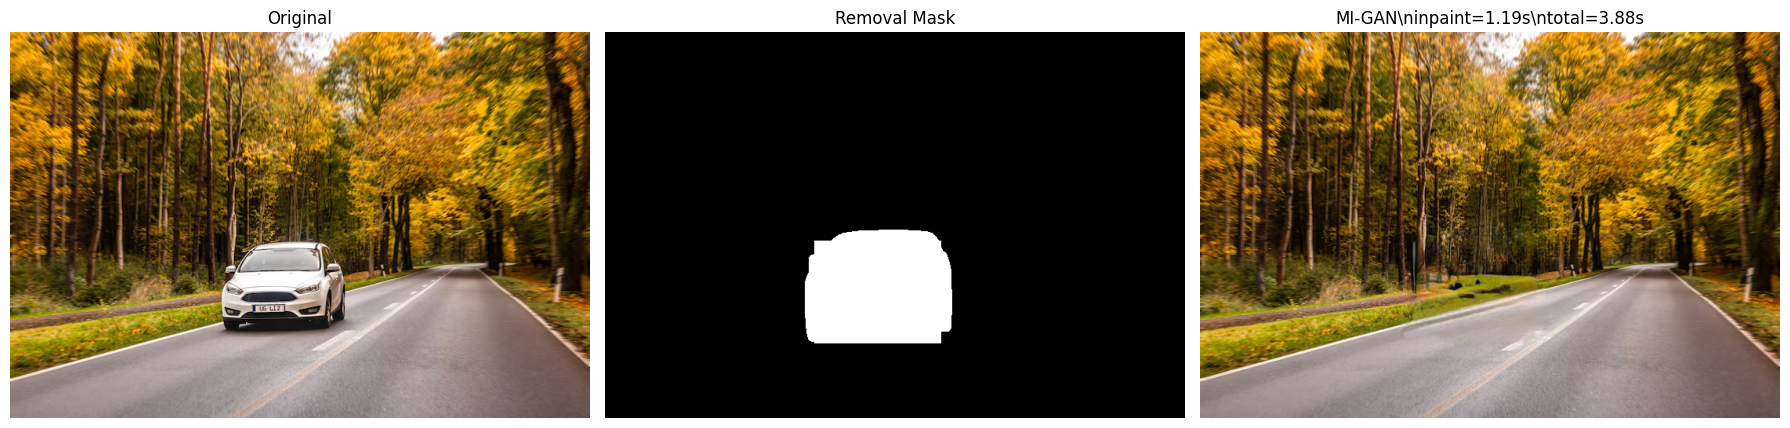

In [23]:
# Single-image MI-GAN vs LaMa comparison

image = cv2.imread(
    os.path.join(
        BASE_DIR,
        "car.jpg"
    )
)

instruction = "Remove the car"

migan_output, migan_mask, migan_meta = (
    e3_remove(
        image,
        instruction,
        method="migan"
    )
)

# lama_output, lama_mask, lama_meta = (
#     e3_remove(
#         image,
#         instruction,
#         method="lama"
#     )
# )

print("MI-GAN metadata:")
print(json.dumps(migan_meta, indent=2))

# print("\\nLaMa metadata:")
# print(json.dumps(lama_meta, indent=2))

show_e3_results(
    image,
    {
        "MI-GAN": (
            migan_output,
            migan_mask,
            migan_meta
        ),
        # "LaMa": (
        #     lama_output,
        #     lama_mask,
        #     lama_meta
        # ),
    }
)

In [16]:
# Fixed benchmark schema: use "action", not "operation".

benchmark_cases = [
    {
        "image": os.path.join(BASE_DIR, "car_2.jpg"),
        "instruction": "Remove the car",
        "action": "remove",
    },
    {
        "image": os.path.join(BASE_DIR, "park_2.jpg"),
        "instruction": "Remove the person",
        "action": "remove",
    },
    {
        "image": os.path.join(BASE_DIR, "road_2.jpg"),
        "instruction": "Remove the bicycle",
        "action": "remove",
    },
]

In [17]:
def benchmark_e3(
    benchmark_cases,
    method,
    iterations=3,
    warmup=1,
    confidence=0.25,
    imgsz=640,
    mask_grow=15,
    shadow_ratio=0.15,
    save_path=None,
):
    rows = []

    for case in benchmark_cases:
        if case.get("action") != "remove":
            continue

        image_path = case["image"]
        instruction = case["instruction"]

        image = cv2.imread(image_path)

        if image is None:
            print("Skipping:", image_path)
            continue

        print(
            f"\\n[{method}] "
            f"{Path(image_path).name} | "
            f"{instruction}"
        )

        for _ in range(warmup):
            try:
                e3_remove(
                    image,
                    instruction,
                    method=method,
                    confidence=confidence,
                    imgsz=imgsz,
                    mask_grow=mask_grow,
                    shadow_ratio=shadow_ratio,
                )
            except Exception as exc:
                print("Warmup error:", exc)

        for _ in range(iterations):
            try:
                start = time.perf_counter()

                _, _, meta = e3_remove(
                    image,
                    instruction,
                    method=method,
                    confidence=confidence,
                    imgsz=imgsz,
                    mask_grow=mask_grow,
                    shadow_ratio=shadow_ratio,
                )

                e2e = (
                    time.perf_counter()
                    - start
                )

                rows.append({
                    "variant":
                        meta["variant"],
                    "image":
                        Path(image_path).name,
                    "instruction":
                        instruction,
                    "resolution":
                        f"{image.shape[1]}x{image.shape[0]}",
                    "end_to_end_latency_ms":
                        e2e * 1000,
                    "detection_time_ms":
                        meta["detection_time_sec"] * 1000,
                    "segmentation_time_ms":
                        meta["segmentation_time_sec"] * 1000,
                    "inpaint_time_ms":
                        meta["inpaint_time_sec"] * 1000,
                    "total_time_ms":
                        meta["total_time_sec"] * 1000,
                    "mask_area_ratio":
                        meta["mask_area_ratio"],
                })

            except Exception as exc:
                print("Run error:", exc)

    df = pd.DataFrame(rows)

    if df.empty:
        summary = pd.DataFrame()
    else:
        summary = (
            df.groupby(
                "variant",
                as_index=False
            )
            .agg(
                mean_latency_ms=(
                    "total_time_ms",
                    "mean"
                ),
                median_latency_ms=(
                    "total_time_ms",
                    "median"
                ),
                std_latency_ms=(
                    "total_time_ms",
                    "std"
                ),
                mean_inpaint_ms=(
                    "inpaint_time_ms",
                    "mean"
                ),
                mean_detection_ms=(
                    "detection_time_ms",
                    "mean"
                ),
                mean_segmentation_ms=(
                    "segmentation_time_ms",
                    "mean"
                ),
            )
        )

    if save_path:
        Path(save_path).parent.mkdir(
            parents=True,
            exist_ok=True
        )
        df.to_csv(
            save_path,
            index=False
        )

    return df, summary

In [18]:
migan_runs, migan_summary = benchmark_e3(
    benchmark_cases,
    method="migan",
    iterations=3,
    warmup=1,
    save_path=os.path.join(
        BENCHMARK_DIR,
        "e3_migan_benchmark.csv"
    )
)

# lama_runs, lama_summary = benchmark_e3(
#     benchmark_cases,
#     method="lama",
#     iterations=3,
#     warmup=1,
#     save_path=os.path.join(
#         BENCHMARK_DIR,
#         "e3_lama_benchmark.csv"
#     )
# )

e3_runs = pd.concat(
    [migan_runs],
    ignore_index=True
)

e3_summary = pd.concat(
    [migan_summary],
    ignore_index=True
)

display(e3_summary)
display(e3_runs)

\n[migan] car_2.jpg | Remove the car
\n[migan] park_2.jpg | Remove the person
\n[migan] road_2.jpg | Remove the bicycle


,variant,mean_latency_ms,median_latency_ms,std_latency_ms,mean_inpaint_ms,mean_detection_ms,mean_segmentation_ms
0,E3-MI-GAN,3504.377164,3469.50572,221.20569,1023.659144,114.209257,2366.508764


,variant,image,instruction,resolution,end_to_end_latency_ms,detection_time_ms,segmentation_time_ms,inpaint_time_ms,total_time_ms,mask_area_ratio
0,E3-MI-GAN,car_2.jpg,Remove the car,740x493,3473.869368,89.075361,2390.801219,989.629140,3469.505720,0.113566
1,E3-MI-GAN,car_2.jpg,Remove the car,740x493,3476.778246,89.699391,2395.526686,986.960342,3472.186419,0.113566
2,E3-MI-GAN,car_2.jpg,Remove the car,740x493,3919.449394,90.619940,2846.683100,977.782108,3915.085148,0.113566
3,E3-MI-GAN,park_2.jpg,Remove the person,612x459,3282.352050,95.000130,2202.720084,981.163778,3278.883992,0.165955
4,E3-MI-GAN,park_2.jpg,Remove the person,612x459,3685.230504,97.901838,2395.032772,1186.911548,3679.846158,0.165955
5,E3-MI-GAN,park_2.jpg,Remove the person,612x459,3278.070593,127.852739,2191.430382,953.507076,3272.790197,0.165955
6,E3-MI-GAN,road_2.jpg,Remove the bicycle,640x640,3720.242372,127.558219,2393.780263,1190.315975,3711.654457,0.120820
7,E3-MI-GAN,road_2.jpg,Remove the bicycle,640x640,3429.484147,173.954639,2270.220531,980.432049,3424.607219,0.120820
8,E3-MI-GAN,road_2.jpg,Remove the bicycle,640x640,3319.610496,136.221054,2212.383838,966.230277,3314.835169,0.120820


## Quality evaluation

Do **not** compute PSNR/SSIM by comparing the removed image against the original image: the original contains the object you intentionally removed, so it is not the correct ground truth.

For quantitative removal quality, use paired data:
- input image containing the object
- clean image showing the true background
- same removal region/mask

For the current `car_2.jpg`, `park_2.jpg`, and `road_2.jpg` examples, the correct evaluation is visual comparison unless you have clean ground-truth images.

In [19]:
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)


def removal_quality_metrics(
    pred_bgr,
    ground_truth_bgr,
    remove_mask,
):
    pred_rgb = cv2.cvtColor(
        pred_bgr,
        cv2.COLOR_BGR2RGB
    )

    gt_rgb = cv2.cvtColor(
        ground_truth_bgr,
        cv2.COLOR_BGR2RGB
    )

    mask = (
        ensure_binary_mask(remove_mask)
        > 0
    )

    if pred_rgb.shape != gt_rgb.shape:
        raise ValueError(
            "Prediction and ground truth must have the same shape."
        )

    ys, xs = np.where(mask)

    if len(xs) == 0:
        raise ValueError(
            "Removal mask is empty."
        )

    x1, x2 = xs.min(), xs.max() + 1
    y1, y2 = ys.min(), ys.max() + 1

    pred_crop = pred_rgb[
        y1:y2,
        x1:x2
    ]

    gt_crop = gt_rgb[
        y1:y2,
        x1:x2
    ]

    mask_crop = mask[
        y1:y2,
        x1:x2
    ]

    pred_eval = gt_crop.copy()
    pred_eval[mask_crop] = (
        pred_crop[mask_crop]
    )

    return {
        "PSNR_dB": float(
            peak_signal_noise_ratio(
                gt_crop,
                pred_eval,
                data_range=255
            )
        ),
        "SSIM": float(
            structural_similarity(
                gt_crop,
                pred_eval,
                channel_axis=2,
                data_range=255
            )
        ),
    }

### What changed versus your current notebook

- Stable Diffusion is **not loaded** in E3.
- Telea pre-fill is **not used** before MI-GAN/LaMa; each learned inpainter sees the original image + the same removal mask.
- The MI-GAN mask is explicitly inverted to match the official ONNX convention.
- LaMa is loaded once and reused.
- The benchmark bug in the original notebook (`operation` in the cases vs `action` in `benchmark_e2`) is fixed.
- Removal and replacement are separated: MI-GAN/LaMa replace only the removal path.